# Project 9: Hospital Appointment Operations Analysis
**Dataset:** `09_hospital_appointments.csv` (500 rows, 9 columns)

**Important:** this is an *operational* dataset. We only talk about attendance, waiting time,
department workload and fees. We make **no medical conclusions**.

**How to read this file:** every `# %%` block is one notebook cell. Each task has a heading,
code (with a comment above every important line), printed output, and a short business interpretation.

**How to run the script:** open a terminal in the project folder and type `python src/hospital_analysis.py`

## Setup: import the libraries

In [1]:
# pandas is used for tables (DataFrames)
import pandas as pd

# NumPy is used for maths such as median, quartiles and standard deviation
import numpy as np

# matplotlib is used to draw charts
import matplotlib.pyplot as plt

# seaborn makes charts look nicer (we use it for the boxplot and heatmap)
import seaborn as sns

# os is used only to create the outputs folder
import os

# base is the folder prefix for the files. Script: "" (run from project folder). Notebook: "../"
base = "../"

# Create the outputs folder if it does not exist yet (exist_ok=True means: no error if it is already there)
os.makedirs(base + "outputs", exist_ok=True)

# Give every chart a clean white grid background
sns.set_style("whitegrid")

# Show all columns when we print a table, so nothing is hidden with "..."
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Task 1: Load the data
We read the CSV file and look at its shape, first rows, data types, summary statistics and info.

In [2]:
# Read the CSV file into a pandas table called df
df = pd.read_csv(base + "data/09_hospital_appointments.csv")

# shape gives (number of rows, number of columns)
print("Shape (rows, columns):", df.shape)

# head() shows the first 5 rows so we can see what the data looks like
print("\nFirst 5 rows:")
print(df.head())

# dtypes shows the data type of each column (number, text, etc.)
print("\nData types:")
print(df.dtypes)

# describe() gives count, mean, min, max and quartiles for number columns
print("\nSummary statistics (describe):")
print(df.describe())

# info() shows non-null counts, which helps us spot missing values
print("\nInfo:")
df.info()

Shape (rows, columns): (500, 9)

First 5 rows:
  Appointment_ID  Age  Department Appointment_Date  Wait_Time_Min Appointment_Type SMS_Reminder Attendance_Status  Consultation_Fee
0        AP00000   18     General       2025-05-04           37.0        Follow-up          Yes          Attended              1200
1        AP00001   32  Pediatrics       2025-01-22           31.0        Follow-up          Yes          Attended              1200
2        AP00002   46     General       2025-02-26           33.0              New          Yes          Attended               700
3        AP00003   49  Cardiology       2025-05-03           11.0              New           No          Attended              1200
4        AP00004   47  Cardiology       2025-05-05           26.0        Follow-up           No          Attended              1200

Data types:
Appointment_ID           str
Age                    int64
Department               str
Appointment_Date         str
Wait_Time_Min        float64
App

In [3]:
# Business interpretation for Task 1
print("Interpretation: the file has", df.shape[0], "appointments and", df.shape[1], "columns.")
print("Only Wait_Time_Min has missing values (490 of 500 are filled), so we must handle that in Task 2.")
print("Appointment_Date is stored as text, so we will convert it to a real date in Task 9.")

Interpretation: the file has 500 appointments and 9 columns.
Only Wait_Time_Min has missing values (490 of 500 are filled), so we must handle that in Task 2.
Appointment_Date is stored as text, so we will convert it to a real date in Task 9.
Appointment_Date is stored as text, so we will convert it to a real date in Task 9.


## Task 2: Find and fill the missing waiting times
**Why the MEDIAN of each department?**
1. The median is the "middle" value, so a few very long waits do not pull it up (the mean can be pulled up).
2. Different departments have different usual waits, so a department median is fairer than one number for everyone.
3. We keep all 500 rows. If we deleted the rows, we would lose their attendance and fee information too.

In [4]:
# Count how many waiting times are missing (isna() marks missing values as True, sum() counts them)
missing_count = df["Wait_Time_Min"].isna().sum()

# Turn the count into a percentage of all rows and round to 2 decimals
missing_percent = round(missing_count / len(df) * 100, 2)

# Print the count and percentage
print("Missing waiting times:", missing_count, "out of", len(df), "rows =", missing_percent, "%")

# Show how many are missing in each department
print("\nMissing waiting times by department:")
print(df[df["Wait_Time_Min"].isna()]["Department"].value_counts())

# Save the missing rows so we can show them again AFTER filling (this is our proof)
missing_rows = df[df["Wait_Time_Min"].isna()]

# Save the average before filling, to compare later
mean_before = round(df["Wait_Time_Min"].mean(), 2)

# Print the rows BEFORE filling (Wait_Time_Min shows NaN, which means missing)
print("\nBEFORE filling:")
print(missing_rows[["Appointment_ID", "Department", "Wait_Time_Min"]])

Missing waiting times: 10 out of 500 rows = 2.0 %

Missing waiting times by department:
Department
General        3
Pediatrics     2
Orthopedics    2
Dermatology    2
Cardiology     1
Name: count, dtype: int64

BEFORE filling:
    Appointment_ID   Department  Wait_Time_Min
125        AP00125   Pediatrics            NaN
158        AP00158   Pediatrics            NaN
199        AP00199  Orthopedics            NaN
220        AP00220      General            NaN
230        AP00230   Cardiology            NaN
366        AP00366      General            NaN
371        AP00371  Dermatology            NaN
392        AP00392      General            NaN
410        AP00410  Orthopedics            NaN
495        AP00495  Dermatology            NaN
495        AP00495  Dermatology            NaN


In [5]:
# For every row, find the median wait of that row's department (transform gives one value per row)
dept_median = df.groupby("Department")["Wait_Time_Min"].transform("median")

# Fill only the missing waiting times with that department median
df["Wait_Time_Min"] = df["Wait_Time_Min"].fillna(dept_median)

# Print the same rows AFTER filling to prove the gaps are gone
print("AFTER filling:")
print(df.loc[missing_rows.index, ["Appointment_ID", "Department", "Wait_Time_Min"]])

# Count the missing values again; it should now be 0
print("\nMissing values now:", df["Wait_Time_Min"].isna().sum())

# Compare the average before and after, to show filling did not change the picture much
mean_after = round(df["Wait_Time_Min"].mean(), 2)
print("Average wait BEFORE filling:", mean_before, "minutes")
print("Average wait AFTER filling :", mean_after, "minutes")

AFTER filling:
    Appointment_ID   Department  Wait_Time_Min
125        AP00125   Pediatrics           30.0
158        AP00158   Pediatrics           30.0
199        AP00199  Orthopedics           25.5
220        AP00220      General           27.0
230        AP00230   Cardiology           24.0
366        AP00366      General           27.0
371        AP00371  Dermatology           32.0
392        AP00392      General           27.0
410        AP00410  Orthopedics           25.5
495        AP00495  Dermatology           32.0

Missing values now: 0
Average wait BEFORE filling: 28.16 minutes
Average wait AFTER filling : 28.15 minutes
Average wait AFTER filling : 28.15 minutes


In [6]:
# Business interpretation for Task 2
print("Interpretation:", missing_count, "waiting times (", missing_percent, "% ) were missing and were filled with the department median.")
print("The average wait stayed almost the same (", mean_before, "->", mean_after, "), so the filling did not distort the data.")

Interpretation: 10 waiting times ( 2.0 % ) were missing and were filled with the department median.
The average wait stayed almost the same ( 28.16 -> 28.15 ), so the filling did not distort the data.
The average wait stayed almost the same ( 28.16 -> 28.15 ), so the filling did not distort the data.


## Task 3: Check duplicate Appointment_ID values

In [7]:
# duplicated() marks an ID as True if it already appeared earlier in the table; sum() counts them
duplicate_count = df["Appointment_ID"].duplicated().sum()

# Count how many different IDs there are
unique_count = df["Appointment_ID"].nunique()

# Print the check results
print("Rows in the table        :", len(df))
print("Unique Appointment_IDs   :", unique_count)
print("Duplicate Appointment_IDs:", duplicate_count)

# If duplicates exist, keep only the first record of each ID; otherwise change nothing
if duplicate_count > 0:
    df = df.drop_duplicates(subset="Appointment_ID", keep="first")
    print("Action: removed the duplicate rows.")
else:
    print("Action: no duplicates found, so no rows were removed.")

# Print the final number of rows
print("Rows after the check     :", len(df))

Rows in the table        : 500
Unique Appointment_IDs   : 500
Duplicate Appointment_IDs: 0
Action: no duplicates found, so no rows were removed.
Rows after the check     : 500
Rows after the check     : 500


In [8]:
# Business interpretation for Task 3
print("Interpretation: every Appointment_ID is unique, so each row is one real appointment and nothing is counted twice.")

Interpretation: every Appointment_ID is unique, so each row is one real appointment and nothing is counted twice.
Interpretation: every Appointment_ID is unique, so each row is one real appointment and nothing is counted twice.


## Task 4: Total appointments and attendance-status percentages

In [9]:
# The total number of appointments is the number of rows
total_appointments = len(df)

# Count how many rows there are for each attendance status
status_counts = df["Attendance_Status"].value_counts()

# Convert the counts into percentages and round to 2 decimals
status_percent = (status_counts / total_appointments * 100).round(2)

# Put counts and percentages side by side in one table
status_table = pd.DataFrame({"Appointments": status_counts, "Percentage": status_percent})

# Print the total and the table
print("Total appointments:", total_appointments)
print(status_table)

# Save each percentage in a simple variable for later use
attended_pct = status_percent["Attended"]
noshow_pct = status_percent["No-show"]
cancelled_pct = status_percent["Cancelled"]

Total appointments: 500
                   Appointments  Percentage
Attendance_Status                          
Attended                    397        79.4
No-show                      60        12.0
Cancelled                    43         8.6
Cancelled                    43         8.6


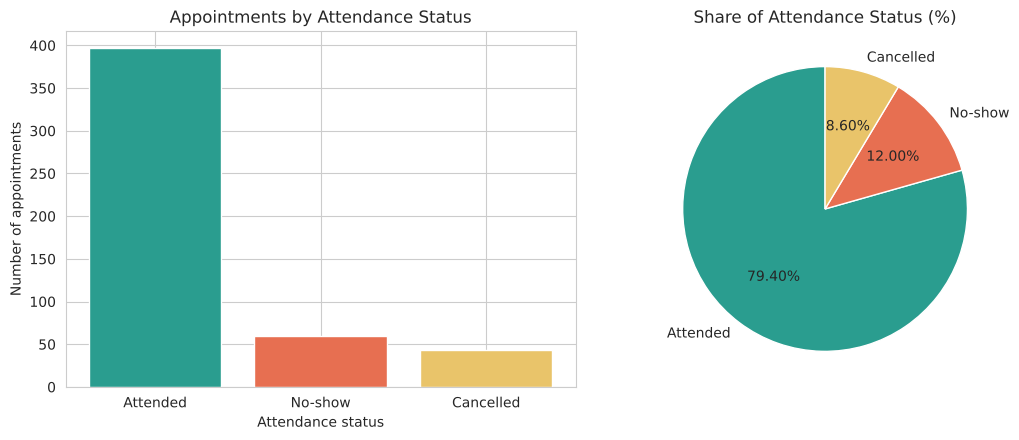

In [10]:
# Chart 1: attendance status as a bar chart and a pie chart side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left chart: bar chart of the counts
axes[0].bar(status_counts.index, status_counts.values, color=["#2a9d8f", "#e76f51", "#e9c46a"])
axes[0].set_title("Appointments by Attendance Status")
axes[0].set_xlabel("Attendance status")
axes[0].set_ylabel("Number of appointments")

# Right chart: pie chart showing the percentages
axes[1].pie(status_counts.values, labels=status_counts.index, autopct="%.2f%%",
            colors=["#2a9d8f", "#e76f51", "#e9c46a"], startangle=90)
axes[1].set_title("Share of Attendance Status (%)")

# Save the chart as a PNG file and show it
plt.tight_layout()
plt.savefig(base + "outputs/chart1_attendance_status.png", dpi=150)
plt.show()

In [11]:
# Business interpretation for Task 4
print("Interpretation:", attended_pct, "% of appointments were attended,", noshow_pct, "% were no-shows and", cancelled_pct, "% were cancelled.")
print("So about", round(noshow_pct + cancelled_pct, 2), "% of booked slots did not turn into a visit. This is the capacity we could try to recover.")

Interpretation: 79.4 % of appointments were attended, 12.0 % were no-shows and 8.6 % were cancelled.
So about 20.6 % of booked slots did not turn into a visit. This is the capacity we could try to recover.
So about 20.6 % of booked slots did not turn into a visit. This is the capacity we could try to recover.


## Task 5: Average waiting time by department (groupby + agg)

In [12]:
# Group the rows by department, then calculate several numbers for each group
wait_by_dept = df.groupby("Department").agg(
    Appointments=("Appointment_ID", "count"),
    Avg_Wait=("Wait_Time_Min", "mean"),
    Median_Wait=("Wait_Time_Min", "median"),
    Max_Wait=("Wait_Time_Min", "max"),
)

# Round to 2 decimals and sort so the longest wait is on top
wait_by_dept = wait_by_dept.round(2).sort_values("Avg_Wait", ascending=False)

# Print the table
print(wait_by_dept)

# Save the names and values of the longest and shortest waits for later
longest_dept = wait_by_dept.index[0]
longest_wait = wait_by_dept["Avg_Wait"].iloc[0]
second_dept = wait_by_dept.index[1]
second_wait = wait_by_dept["Avg_Wait"].iloc[1]
shortest_dept = wait_by_dept.index[-1]
shortest_wait = wait_by_dept["Avg_Wait"].iloc[-1]

             Appointments  Avg_Wait  Median_Wait  Max_Wait
Department                                                
Pediatrics            107     30.42         30.0      58.0
Dermatology           105     29.94         32.0      65.0
General                98     27.11         27.0      64.0
Orthopedics            92     27.10         25.5      71.0
Cardiology             98     25.80         24.0      60.0
Cardiology             98     25.80         24.0      60.0


In [13]:
# Business interpretation for Task 5
print("Interpretation:", longest_dept, "has the longest average wait (", longest_wait, "min) and", shortest_dept, "has the shortest (", shortest_wait, "min).")
print("The gap is", round(longest_wait - shortest_wait, 2), "minutes, so queue improvements should start with", longest_dept, "and", second_dept, ".")

Interpretation: Pediatrics has the longest average wait ( 30.42 min) and Cardiology has the shortest ( 25.8 min).
The gap is 4.62 minutes, so queue improvements should start with Pediatrics and Dermatology .
The gap is 4.62 minutes, so queue improvements should start with Pediatrics and Dermatology .


## Task 6: Which departments have the highest no-show percentage?

In [14]:
# crosstab counts each department/status pair; normalize="index" turns each row into fractions that add up to 1
dept_status = pd.crosstab(df["Department"], df["Attendance_Status"], normalize="index")

# Multiply by 100 to get percentages and round to 2 decimals
dept_status = (dept_status * 100).round(2)

# Keep only the No-show column and sort from highest to lowest
noshow_by_dept = dept_status["No-show"].sort_values(ascending=False)

# Print the no-show percentage for every department
print("No-show percentage by department:")
print(noshow_by_dept)

# Also print the actual number of no-shows per department
print("\nNumber of no-shows by department:")
print(df[df["Attendance_Status"] == "No-show"]["Department"].value_counts())

No-show percentage by department:
Department
Pediatrics     14.95
Dermatology    14.29
Orthopedics    13.04
General         9.18
Cardiology      8.16
Name: No-show, dtype: float64

Number of no-shows by department:
Department
Pediatrics     16
Dermatology    15
Orthopedics    12
General         9
Cardiology      8
Name: count, dtype: int64
Name: count, dtype: int64


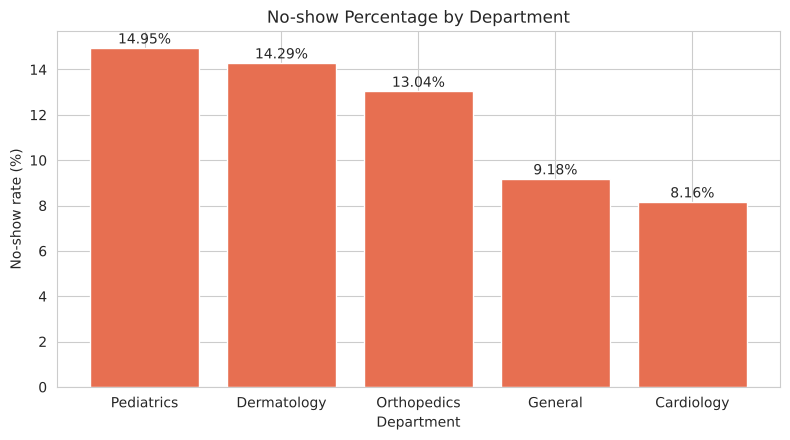

In [15]:
# Chart 2: no-show percentage by department
plt.figure(figsize=(8, 4.5))
plt.bar(noshow_by_dept.index, noshow_by_dept.values, color="#e76f51")
plt.title("No-show Percentage by Department")
plt.xlabel("Department")
plt.ylabel("No-show rate (%)")

# Write the value above each bar so it is easy to read
for position, value in enumerate(noshow_by_dept.values):
    plt.text(position, value + 0.2, str(value) + "%", ha="center")

plt.tight_layout()
plt.savefig(base + "outputs/chart2_noshow_by_department.png", dpi=150)
plt.show()

In [16]:
# Business interpretation for Task 6
top1 = noshow_by_dept.index[0]
top2 = noshow_by_dept.index[1]
top3 = noshow_by_dept.index[2]
print("Interpretation: the highest no-show rates are", top1, "(", noshow_by_dept.iloc[0], "%),", top2, "(", noshow_by_dept.iloc[1], "%) and", top3, "(", noshow_by_dept.iloc[2], "%).")
print("The lowest is", noshow_by_dept.index[-1], "(", noshow_by_dept.iloc[-1], "%). Each department has only about 100 rows, so treat these as a guide, not exact.")

Interpretation: the highest no-show rates are Pediatrics ( 14.95 %), Dermatology ( 14.29 %) and Orthopedics ( 13.04 %).
The lowest is Cardiology ( 8.16 %). Each department has only about 100 rows, so treat these as a guide, not exact.
The lowest is Cardiology ( 8.16 %). Each department has only about 100 rows, so treat these as a guide, not exact.


## Task 7: No-show rate for SMS reminder Yes vs No (pd.crosstab)

In [17]:
# Table of COUNTS: rows = SMS reminder, columns = attendance status; margins=True adds totals
sms_counts = pd.crosstab(df["SMS_Reminder"], df["Attendance_Status"], margins=True)

# Table of ROW PERCENTAGES: each row adds up to 100%
sms_percent = pd.crosstab(df["SMS_Reminder"], df["Attendance_Status"], normalize="index")
sms_percent = (sms_percent * 100).round(2)

# Print both tables
print("Counts:")
print(sms_counts)
print("\nRow percentages (%):")
print(sms_percent)

# Take out the two no-show rates we want to compare
noshow_with_sms = sms_percent.loc["Yes", "No-show"]
noshow_without_sms = sms_percent.loc["No", "No-show"]

# Difference in percentage points
sms_gap = round(noshow_without_sms - noshow_with_sms, 2)
print("\nNo-show rate WITH reminder   :", noshow_with_sms, "%")
print("No-show rate WITHOUT reminder:", noshow_without_sms, "%")
print("Difference:", sms_gap, "percentage points")

Counts:
Attendance_Status  Attended  Cancelled  No-show  All
SMS_Reminder                                        
No                      198         21       34  253
Yes                     199         22       26  247
All                     397         43       60  500

Row percentages (%):
Attendance_Status  Attended  Cancelled  No-show
SMS_Reminder                                   
No                    78.26       8.30    13.44
Yes                   80.57       8.91    10.53

No-show rate WITH reminder   : 10.53 %
No-show rate WITHOUT reminder: 13.44 %
Difference: 2.91 percentage points
Difference: 2.91 percentage points


In [18]:
# Business interpretation for Task 7
print("Interpretation: patients who got an SMS had a lower no-show rate (", noshow_with_sms, "%) than those who did not (", noshow_without_sms, "%).")
print("The gap is", sms_gap, "points. With only about 250 rows in each group, treat this as a good sign, not final proof.")

Interpretation: patients who got an SMS had a lower no-show rate ( 10.53 %) than those who did not ( 13.44 %).
The gap is 2.91 points. With only about 250 rows in each group, treat this as a good sign, not final proof.
The gap is 2.91 points. With only about 250 rows in each group, treat this as a good sign, not final proof.


## Task 8: Average consultation fee by department

In [19]:
# Group by department and calculate the average, smallest and largest fee
fee_by_dept = df.groupby("Department").agg(
    Avg_Fee=("Consultation_Fee", "mean"),
    Min_Fee=("Consultation_Fee", "min"),
    Max_Fee=("Consultation_Fee", "max"),
)

# Round to 2 decimals and sort from highest average fee to lowest
fee_by_dept = fee_by_dept.round(2).sort_values("Avg_Fee", ascending=False)

# Make a copy for printing, with thousands separators (for example 1,200.00)
fee_show = fee_by_dept.copy()
fee_show["Avg_Fee"] = fee_show["Avg_Fee"].map("{:,.2f}".format)
fee_show["Min_Fee"] = fee_show["Min_Fee"].map("{:,.0f}".format)
fee_show["Max_Fee"] = fee_show["Max_Fee"].map("{:,.0f}".format)
print(fee_show)

# Overall average fee across all appointments
overall_avg_fee = round(df["Consultation_Fee"].mean(), 2)
print("\nOverall average fee:", "{:,.2f}".format(overall_avg_fee))

            Avg_Fee Min_Fee Max_Fee
Department                         
General      777.55     300   1,200
Pediatrics   748.60     300   1,200
Dermatology  748.57     300   1,200
Orthopedics  689.13     300   1,200
Cardiology   688.78     300   1,200

Overall average fee: 731.60
Overall average fee: 731.60


In [20]:
# Business interpretation for Task 8
print("Interpretation:", fee_by_dept.index[0], "has the highest average fee (", "{:,.2f}".format(fee_by_dept["Avg_Fee"].iloc[0]), ") and", fee_by_dept.index[-1], "the lowest (", "{:,.2f}".format(fee_by_dept["Avg_Fee"].iloc[-1]), ").")
print("The differences between departments are small, because every department has fees from 300 to 1,200.")

Interpretation: General has the highest average fee ( 777.55 ) and Cardiology the lowest ( 688.78 ).
The differences between departments are small, because every department has fees from 300 to 1,200.
The differences between departments are small, because every department has fees from 300 to 1,200.


## Task 9: Appointment volume by date and department
First we convert `Appointment_Date` from text to a real date with `pd.to_datetime`, and check that it worked.

In [21]:
# Before converting, look at the data type (text)
print("Type BEFORE:", df["Appointment_Date"].dtype)

# Convert the text to real dates (errors="coerce" turns bad dates into NaT instead of crashing)
df["Appointment_Date"] = pd.to_datetime(df["Appointment_Date"], errors="coerce")

# Check the new data type
print("Type AFTER :", df["Appointment_Date"].dtype)

# Count dates that could not be read (should be 0)
print("Dates that failed to convert:", df["Appointment_Date"].isna().sum())

# Show the first and last date to confirm they make sense
print("First date:", df["Appointment_Date"].min().date())
print("Last date :", df["Appointment_Date"].max().date())

# Make a Month column (like 2025-01) and a Weekday column (like Monday) for later use
df["Month"] = df["Appointment_Date"].dt.to_period("M").astype(str)
df["Weekday"] = df["Appointment_Date"].dt.day_name()

Type BEFORE: str
Type AFTER : datetime64[us]
Dates that failed to convert: 0
First date: 2025-01-01
Last date : 2025-06-29
Last date : 2025-06-29


In [22]:
# DAILY trend: count appointments on each date
daily_counts = df.groupby("Appointment_Date").size()

# Print simple facts about the daily volume
print("Days with at least one appointment:", len(daily_counts))
print("Average appointments per day      :", round(daily_counts.mean(), 2))
print("\nBusiest 5 days:")
print(daily_counts.sort_values(ascending=False).head(5))

# Daily volume by department: average appointments per day for each department
print("\nAverage appointments per day, by department:")
print((df["Department"].value_counts() / len(daily_counts)).round(2))

Days with at least one appointment: 163
Average appointments per day      : 3.07

Busiest 5 days:
Appointment_Date
2025-02-05    10
2025-05-03     8
2025-02-27     8
2025-02-22     7
2025-02-19     7
dtype: int64

Average appointments per day, by department:
Department
Pediatrics     0.66
Dermatology    0.64
General        0.60
Cardiology     0.60
Orthopedics    0.56
Name: count, dtype: float64
Name: count, dtype: float64


In [23]:
# MONTHLY trend: count appointments in each month
monthly_counts = df.groupby("Month").size()
print("Appointments per month:")
print(monthly_counts)

# PIVOT TABLE: departments in rows, months in columns, counts inside; margins=True adds totals
dept_month = pd.pivot_table(df, index="Department", columns="Month",
                            values="Appointment_ID", aggfunc="count", margins=True)
print("\nDepartment x Month pivot table:")
print(dept_month)

# Find the busiest and quietest month
peak_month = monthly_counts.idxmax()
low_month = monthly_counts.idxmin()

Appointments per month:
Month
2025-01     71
2025-02    106
2025-03     80
2025-04     82
2025-05     88
2025-06     73
dtype: int64

Department x Month pivot table:
Month        2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  All
Department                                                            
Cardiology        15       17       12       18       14       22   98
Dermatology       19       20       18       14       19       15  105
General           14       28       17       16       13       10   98
Orthopedics        5       17       15       19       23       13   92
Pediatrics        18       24       18       15       19       13  107
All               71      106       80       82       88       73  500
All               71      106       80       82       88       73  500


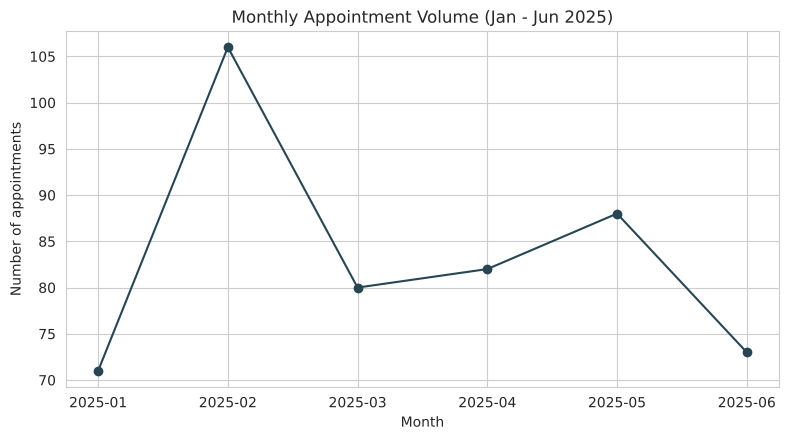

In [24]:
# Chart 4: monthly volume line chart
plt.figure(figsize=(8, 4.5))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", color="#264653")
plt.title("Monthly Appointment Volume (Jan - Jun 2025)")
plt.xlabel("Month")
plt.ylabel("Number of appointments")
plt.tight_layout()
plt.savefig(base + "outputs/chart4_monthly_volume.png", dpi=150)
plt.show()

In [25]:
# Business interpretation for Task 9
print("Interpretation: the busiest month was", peak_month, "(", monthly_counts.max(), "appointments) and the quietest was", low_month, "(", monthly_counts.min(), ").")
print("Volume is fairly steady outside the peak, so staffing can follow a simple monthly plan with extra cover in the peak month.")

Interpretation: the busiest month was 2025-02 ( 106 appointments) and the quietest was 2025-01 ( 71 ).
Volume is fairly steady outside the peak, so staffing can follow a simple monthly plan with extra cover in the peak month.
Volume is fairly steady outside the peak, so staffing can follow a simple monthly plan with extra cover in the peak month.


## Task 10: Waiting time for New vs Follow-up appointments

In [26]:
# Group by appointment type and calculate wait statistics
wait_by_type = df.groupby("Appointment_Type").agg(
    Appointments=("Appointment_ID", "count"),
    Avg_Wait=("Wait_Time_Min", "mean"),
    Median_Wait=("Wait_Time_Min", "median"),
    Max_Wait=("Wait_Time_Min", "max"),
)
wait_by_type = wait_by_type.round(2)
print(wait_by_type)

# Difference between the two averages
type_gap = round(wait_by_type.loc["Follow-up", "Avg_Wait"] - wait_by_type.loc["New", "Avg_Wait"], 2)
print("\nFollow-up minus New (minutes):", type_gap)

                  Appointments  Avg_Wait  Median_Wait  Max_Wait
Appointment_Type                                               
Follow-up                  243     28.26         27.0      71.0
New                        257     28.05         28.0      69.0

Follow-up minus New (minutes): 0.21
Follow-up minus New (minutes): 0.21


In [27]:
# Business interpretation for Task 10
print("Interpretation: New and Follow-up patients wait almost the same time (gap of only", abs(type_gap), "minutes).")
print("So the appointment type is not the cause of long waits; look at departments and time slots instead.")

Interpretation: New and Follow-up patients wait almost the same time (gap of only 0.21 minutes).
So the appointment type is not the cause of long waits; look at departments and time slots instead.
So the appointment type is not the cause of long waits; look at departments and time slots instead.


## Task 11: Median, quartiles and standard deviation with NumPy

In [28]:
# Turn the waiting-time column into a NumPy array
wait_values = df["Wait_Time_Min"].to_numpy()

# Median = the middle value
median_wait = np.median(wait_values)

# Q1 = 25th percentile, Q3 = 75th percentile
q1 = np.percentile(wait_values, 25)
q3 = np.percentile(wait_values, 75)

# Standard deviation tells how spread out the waits are (ddof=1 is the usual sample version)
std_wait = np.std(wait_values, ddof=1)

# Print the results rounded to 2 decimals
print("Median wait :", round(median_wait, 2), "minutes")
print("Q1 (25%)    :", round(q1, 2), "minutes")
print("Q3 (75%)    :", round(q3, 2), "minutes")
print("Std dev     :", round(std_wait, 2), "minutes")

Median wait : 27.5 minutes
Q1 (25%)    : 18.0 minutes
Q3 (75%)    : 38.0 minutes
Std dev     : 14.29 minutes
Std dev     : 14.29 minutes


In [29]:
# Business interpretation for Task 11
print("Interpretation: the typical wait is", round(median_wait, 2), "minutes, and the middle half of patients wait between", round(q1, 2), "and", round(q3, 2), "minutes.")
print("A standard deviation of", round(std_wait, 2), "minutes means waits vary a lot from patient to patient.")

Interpretation: the typical wait is 27.5 minutes, and the middle half of patients wait between 18.0 and 38.0 minutes.
A standard deviation of 14.29 minutes means waits vary a lot from patient to patient.
A standard deviation of 14.29 minutes means waits vary a lot from patient to patient.


## Task 12: Unusually long waits with the IQR rule
**The rule in one sentence:** a wait is "unusually long" if it is more than Q3 + 1.5 x IQR, which means it is much
longer than what the middle group of patients experiences (IQR = Q3 - Q1).

In [30]:
# IQR = the width of the middle half of the data
iqr = q3 - q1

# Upper limit of the rule
upper_limit = q3 + 1.5 * iqr
print("Q1 =", q1, " Q3 =", q3, " IQR =", iqr)
print("Upper limit = Q3 + 1.5 x IQR =", upper_limit, "minutes")

# Keep only the rows with a wait above the upper limit
outliers = df[df["Wait_Time_Min"] > upper_limit]
print("\nNumber of unusually long waits:", len(outliers), "(", round(len(outliers) / len(df) * 100, 2), "% of all appointments )")

# Show those rows
print("\nThe outlier rows:")
print(outliers[["Appointment_ID", "Department", "Appointment_Date", "Wait_Time_Min", "Appointment_Type", "Attendance_Status"]])

# Share of outliers per department (departments with none show 0)
outlier_counts = outliers["Department"].value_counts()
all_departments = df["Department"].unique()
outlier_counts = outlier_counts.reindex(all_departments, fill_value=0)

# Only divide if at least one outlier exists (avoids dividing by zero)
if len(outliers) > 0:
    outlier_share = (outlier_counts / len(outliers) * 100).round(2)
else:
    outlier_share = outlier_counts

# Put counts and shares in one table
outlier_table = pd.DataFrame({"Outliers": outlier_counts, "Share_of_Outliers": outlier_share})
print("\nOutliers by department:")
print(outlier_table)

Q1 = 18.0  Q3 = 38.0  IQR = 20.0
Upper limit = Q3 + 1.5 x IQR = 68.0 minutes

Number of unusually long waits: 2 ( 0.4 % of all appointments )

The outlier rows:
    Appointment_ID   Department Appointment_Date  Wait_Time_Min Appointment_Type Attendance_Status
121        AP00121  Orthopedics       2025-05-17           69.0              New           No-show
226        AP00226  Orthopedics       2025-03-27           71.0        Follow-up          Attended

Outliers by department:
             Outliers  Share_of_Outliers
Department                              
General             0                0.0
Pediatrics          0                0.0
Cardiology          0                0.0
Orthopedics         2              100.0
Dermatology         0                0.0
Dermatology         0                0.0


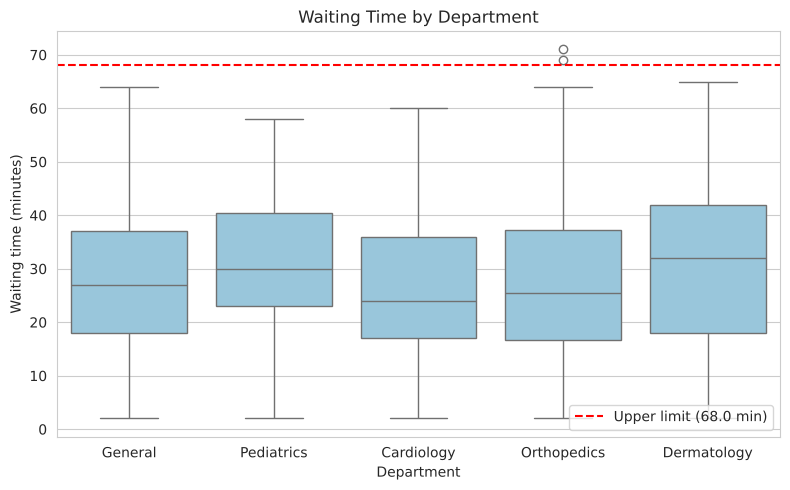

In [31]:
# Chart 3: boxplot of waiting time by department (dots above the box are the long waits)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Department", y="Wait_Time_Min", color="#8ecae6")
plt.axhline(upper_limit, color="red", linestyle="--", label="Upper limit (" + str(upper_limit) + " min)")
plt.title("Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Waiting time (minutes)")
# Put the legend at the bottom right so it does not cover the outlier dots
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(base + "outputs/chart3_wait_boxplot.png", dpi=150)
plt.show()

In [32]:
# Business interpretation for Task 12
print("Interpretation: only", len(outliers), "appointments (", round(len(outliers) / len(df) * 100, 2), "% ) waited more than", upper_limit, "minutes.")
print("Extreme waits are rare, so each case can be checked one by one for a cause such as a late start or a walk-in rush.")

Interpretation: only 2 appointments ( 0.4 % ) waited more than 68.0 minutes.
Extreme waits are rare, so each case can be checked one by one for a cause such as a late start or a walk-in rush.
Extreme waits are rare, so each case can be checked one by one for a cause such as a late start or a walk-in rush.


## Task 13: Waiting-time groups with pd.cut()

In [33]:
# Group edges: 0-15, 16-30, 31-45, 46 and above (-0.01 makes sure a wait of 0 is included)
edges = [-0.01, 15, 30, 45, 1000]

# Names for the four groups
group_names = ["Short (0-15)", "Moderate (16-30)", "Long (31-45)", "Very Long (46+)"]

# pd.cut puts every waiting time into one group
df["Wait_Group"] = pd.cut(df["Wait_Time_Min"], bins=edges, labels=group_names)

# Count appointments in each group (reindex keeps the order Short -> Very Long)
group_counts = df["Wait_Group"].value_counts().reindex(group_names)

# Percentage in each group, rounded to 2 decimals
group_percent = (group_counts / len(df) * 100).round(2)

# Put them in one table and print
group_table = pd.DataFrame({"Appointments": group_counts, "Percentage": group_percent})
print(group_table)

# Share of appointments that wait more than 30 minutes (Long + Very Long)
over_30_pct = round(group_percent["Long (31-45)"] + group_percent["Very Long (46+)"], 2)
over_30_count = group_counts["Long (31-45)"] + group_counts["Very Long (46+)"]
print("\nWaiting more than 30 minutes:", over_30_count, "appointments =", over_30_pct, "%")

                  Appointments  Percentage
Wait_Group                                
Short (0-15)                95        19.0
Moderate (16-30)           197        39.4
Long (31-45)               147        29.4
Very Long (46+)             61        12.2

Waiting more than 30 minutes: 208 appointments = 41.6 %
Waiting more than 30 minutes: 208 appointments = 41.6 %


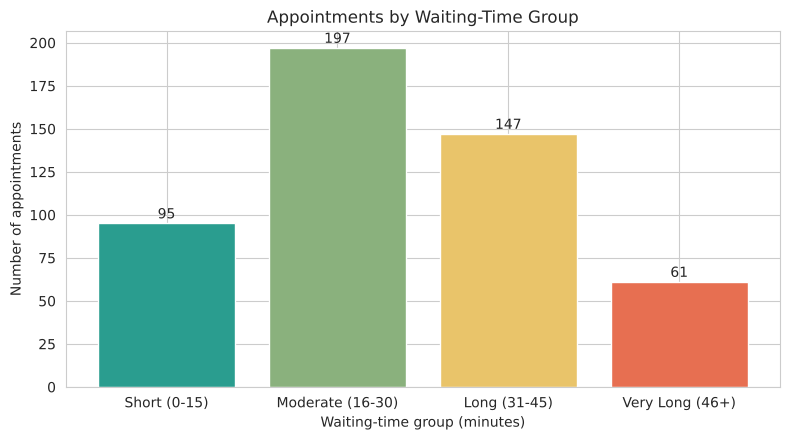

In [34]:
# Chart 5: waiting-time groups bar chart
plt.figure(figsize=(8, 4.5))
plt.bar(group_counts.index, group_counts.values, color=["#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51"])
plt.title("Appointments by Waiting-Time Group")
plt.xlabel("Waiting-time group (minutes)")
plt.ylabel("Number of appointments")

# Write the count above each bar
for position, value in enumerate(group_counts.values):
    plt.text(position, value + 3, str(value), ha="center")

plt.tight_layout()
plt.savefig(base + "outputs/chart5_wait_groups.png", dpi=150)
plt.show()

In [35]:
# Business interpretation for Task 13
print("Interpretation: the Moderate group is the biggest, but", over_30_pct, "% of appointments wait more than 30 minutes.")
print("Moving patients from the Long and Very Long groups into the Moderate group is the clearest way to improve the patient experience.")

Interpretation: the Moderate group is the biggest, but 41.6 % of appointments wait more than 30 minutes.
Moving patients from the Long and Very Long groups into the Moderate group is the clearest way to improve the patient experience.
Moving patients from the Long and Very Long groups into the Moderate group is the clearest way to improve the patient experience.


## Task 14: Estimated fees for ATTENDED appointments only
**Why exclude the other rows?** A fee is only earned when the patient actually comes. No-show and Cancelled rows still show a fee
in the data, but that money was never collected, so including them would overestimate income.

In [36]:
# Keep only the rows where the patient attended
attended = df[df["Attendance_Status"] == "Attended"]

# Proof: compare all rows with attended rows only
print("ALL rows      :", len(df), "rows, fee total =", "{:,}".format(df["Consultation_Fee"].sum()))
print("ATTENDED only :", len(attended), "rows, fee total =", "{:,}".format(attended["Consultation_Fee"].sum()))

# Overall estimated fees
total_fees = attended["Consultation_Fee"].sum()
print("\nEstimated total fees (attended only):", "{:,}".format(total_fees))

# Fees listed on rows that were not attended (not counted)
not_attended_fees = df["Consultation_Fee"].sum() - total_fees
print("Fees listed on No-show / Cancelled rows (not counted):", "{:,}".format(not_attended_fees))

# Estimated fees by department
fees_by_dept = attended.groupby("Department").agg(
    Attended_Visits=("Appointment_ID", "count"),
    Total_Fees=("Consultation_Fee", "sum"),
)
fees_by_dept = fees_by_dept.sort_values("Total_Fees", ascending=False)

# Share of the total, rounded to 2 decimals
fees_by_dept["Share_Percent"] = (fees_by_dept["Total_Fees"] / total_fees * 100).round(2)

# Print with thousands separators (a copy is used so the numbers stay numbers)
fees_show = fees_by_dept.copy()
fees_show["Total_Fees"] = fees_show["Total_Fees"].map("{:,}".format)
print("\nEstimated fees by department:")
print(fees_show)

# Fee value on no-show rows only (used in the recommendations)
noshow_fees = df[df["Attendance_Status"] == "No-show"]["Consultation_Fee"].sum()

ALL rows      : 500 rows, fee total = 365,800
ATTENDED only : 397 rows, fee total = 296,200

Estimated total fees (attended only): 296,200
Fees listed on No-show / Cancelled rows (not counted): 69,600

Estimated fees by department:
             Attended_Visits Total_Fees  Share_Percent
Department                                            
Dermatology               85     64,900          21.91
Pediatrics                81     62,500          21.10
General                   78     62,100          20.97
Cardiology                82     58,400          19.72
Orthopedics               71     48,300          16.31
Orthopedics               71     48,300          16.31


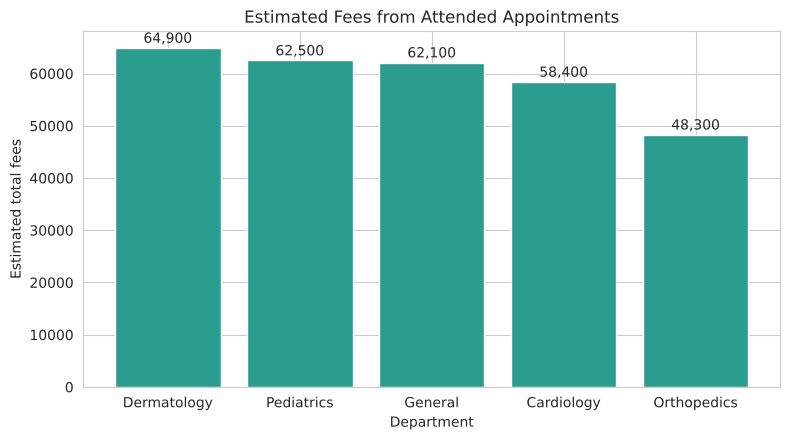

In [37]:
# Chart 6: estimated fees by department
plt.figure(figsize=(8, 4.5))
plt.bar(fees_by_dept.index, fees_by_dept["Total_Fees"], color="#2a9d8f")
plt.title("Estimated Fees from Attended Appointments")
plt.xlabel("Department")
plt.ylabel("Estimated total fees")

# Write the total above each bar, with thousands separators
for position, value in enumerate(fees_by_dept["Total_Fees"].values):
    plt.text(position, value + 1000, "{:,}".format(value), ha="center")

plt.tight_layout()
plt.savefig(base + "outputs/chart6_fees_by_department.png", dpi=150)
plt.show()

In [38]:
# Business interpretation for Task 14
print("Interpretation: attended visits bring in an estimated", "{:,}".format(total_fees), "in fees, not the", "{:,}".format(df["Consultation_Fee"].sum()), "you get by adding every row.")
print(fees_by_dept.index[0], "earns the most (", "{:,}".format(fees_by_dept["Total_Fees"].iloc[0]), ") and", fees_by_dept.index[-1], "the least (", "{:,}".format(fees_by_dept["Total_Fees"].iloc[-1]), ").")

Interpretation: attended visits bring in an estimated 296,200 in fees, not the 365,800 you get by adding every row.
Dermatology earns the most ( 64,900 ) and Orthopedics the least ( 48,300 ).
Dermatology earns the most ( 64,900 ) and Orthopedics the least ( 48,300 ).


## Department summary table (main deliverable)
One table with appointments, average wait, no-show % and average fee for each department.

In [39]:
# Build the summary table from the pieces we already calculated
dept_summary = pd.DataFrame({
    "Appointments": df["Department"].value_counts(),
    "Avg_Wait_Min": df.groupby("Department")["Wait_Time_Min"].mean().round(2),
    "NoShow_Percent": dept_status["No-show"],
    "Avg_Fee": df.groupby("Department")["Consultation_Fee"].mean().round(2),
    "Attended_Fees": fees_by_dept["Total_Fees"],
})

# Sort by number of appointments
dept_summary = dept_summary.sort_values("Appointments", ascending=False)

# Save the table as a CSV file
dept_summary.to_csv(base + "outputs/department_summary.csv")

# Print with thousands separators on the fee columns
summary_show = dept_summary.copy()
summary_show["Avg_Fee"] = summary_show["Avg_Fee"].map("{:,.2f}".format)
summary_show["Attended_Fees"] = summary_show["Attended_Fees"].map("{:,}".format)
print(summary_show)

             Appointments  Avg_Wait_Min  NoShow_Percent Avg_Fee Attended_Fees
Department                                                                   
Pediatrics            107         30.42           14.95  748.60        62,500
Dermatology           105         29.94           14.29  748.57        64,900
Cardiology             98         25.80            8.16  688.78        58,400
General                98         27.11            9.18  777.55        62,100
Orthopedics            92         27.10           13.04  689.13        48,300
Orthopedics            92         27.10           13.04  689.13        48,300


## Optional extra: age group, weekday and heatmap
These are used only as scheduling information. We make no medical conclusions.

In [40]:
# Make a True/False column: True when the appointment was a no-show
df["NoShow_Flag"] = df["Attendance_Status"] == "No-show"

# Age groups for scheduling: 0-12, 13-17, 18-35, 36-59, 60 and above
age_edges = [0, 12, 17, 35, 59, 120]
age_names = ["0-12", "13-17", "18-35", "36-59", "60+"]
df["Age_Group"] = pd.cut(df["Age"], bins=age_edges, labels=age_names)

# The average of True/False gives the share of no-shows; multiply by 100 for percent
age_noshow = (df.groupby("Age_Group", observed=True)["NoShow_Flag"].mean() * 100).round(2)
print("No-show % by age group:")
print(age_noshow)

# Same idea for weekdays, in calendar order
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_noshow = (df.groupby("Weekday")["NoShow_Flag"].mean() * 100).round(2)
weekday_noshow = weekday_noshow.reindex(day_order)
print("\nNo-show % by weekday:")
print(weekday_noshow)

# Number of appointments on each weekday (used in the recommendations)
weekday_counts = df["Weekday"].value_counts().reindex(day_order)

# Heatmap table: average wait for each department and appointment type
heat_table = df.pivot_table(index="Department", columns="Appointment_Type", values="Wait_Time_Min", aggfunc="mean").round(2)
print("\nAverage wait: department x appointment type")
print(heat_table)

No-show % by age group:
Age_Group
0-12     14.93
13-17    11.11
18-35     7.08
36-59     9.23
60+      16.88
Name: NoShow_Flag, dtype: float64

No-show % by weekday:
Weekday
Monday        8.62
Tuesday      11.59
Wednesday    10.45
Thursday      8.24
Friday       12.50
Saturday     20.29
Sunday       12.50
Name: NoShow_Flag, dtype: float64

Average wait: department x appointment type
Appointment_Type  Follow-up    New
Department                        
Cardiology            29.38  23.62
Dermatology           28.48  31.89
General               26.44  27.76
Orthopedics           26.96  27.24
Pediatrics            30.06  30.76
Pediatrics            30.06  30.76


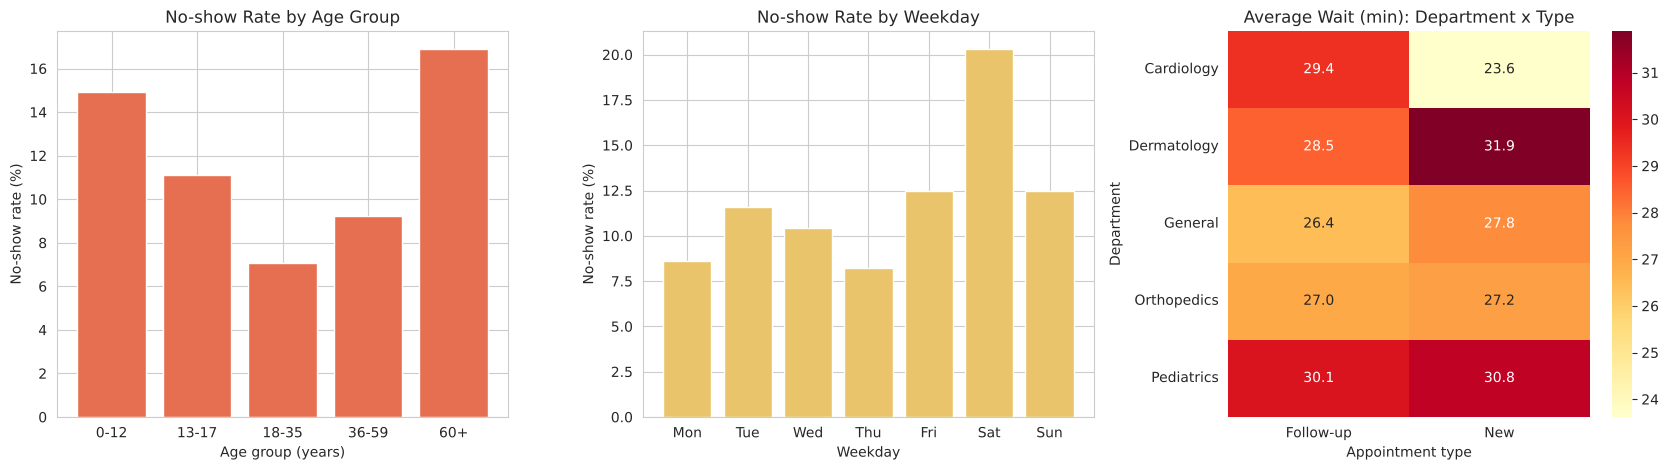

In [41]:
# Extra chart: three small charts in one picture
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Chart A: no-show by age group
axes[0].bar(age_noshow.index.astype(str), age_noshow.values, color="#e76f51")
axes[0].set_title("No-show Rate by Age Group")
axes[0].set_xlabel("Age group (years)")
axes[0].set_ylabel("No-show rate (%)")

# Chart B: no-show by weekday (first 3 letters of each day so labels fit)
axes[1].bar(weekday_noshow.index.str[:3], weekday_noshow.values, color="#e9c46a")
axes[1].set_title("No-show Rate by Weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("No-show rate (%)")

# Chart C: heatmap of average wait
sns.heatmap(heat_table, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[2])
axes[2].set_title("Average Wait (min): Department x Type")
axes[2].set_xlabel("Appointment type")
axes[2].set_ylabel("Department")

plt.tight_layout()
plt.savefig(base + "outputs/chart7_extra_age_weekday_heatmap.png", dpi=150)
plt.show()

In [42]:
# Business interpretation for the extra analysis
print("Interpretation: the no-show rate is highest for age group", age_noshow.idxmax(), "(", age_noshow.max(), "%) and lowest for", age_noshow.idxmin(), "(", age_noshow.min(), "%).")
print("By weekday it is highest on", weekday_noshow.idxmax(), "(", weekday_noshow.max(), "%). These are scheduling patterns only.")

Interpretation: the no-show rate is highest for age group 60+ ( 16.88 %) and lowest for 18-35 ( 7.08 %).
By weekday it is highest on Saturday ( 20.29 %). These are scheduling patterns only.
By weekday it is highest on Saturday ( 20.29 %). These are scheduling patterns only.


## Task 15: Five operational recommendations
Every number below comes from the results above (printed by the code, not typed by hand).

In [43]:
# Recommendation 1 numbers: SMS reminders
rec1 = ("1. Send an SMS reminder for every appointment. No-show rate is " + str(noshow_without_sms) +
        "% without a reminder and " + str(noshow_with_sms) + "% with one, a gap of " + str(sms_gap) +
        " points. All no-shows together hold " + "{:,}".format(noshow_fees) + " in listed fees.")

# Recommendation 2 numbers: overbooking in the two highest no-show departments
slots_per_extra = round(100 / ((noshow_by_dept.iloc[0] + noshow_by_dept.iloc[1]) / 2))
rec2 = ("2. Allow careful overbooking in " + top1 + " and " + top2 + ". Their no-show rates are " +
        str(noshow_by_dept.iloc[0]) + "% and " + str(noshow_by_dept.iloc[1]) + "%, about 1 empty slot in every " +
        str(slots_per_extra) + ". Adding 1 extra booking per " + str(slots_per_extra) + " slots can refill them.")

# Recommendation 3 numbers: staff the departments with the longest waits
longest_over30 = round(pd.crosstab(df["Department"], df["Wait_Group"], normalize="index").loc[longest_dept, ["Long (31-45)", "Very Long (46+)"]].sum() * 100, 2)
rec3 = ("3. Add staff or extra slots at busy times in " + longest_dept + " (" + str(longest_wait) + " min average wait) and " +
        second_dept + " (" + str(second_wait) + " min), compared with " + str(shortest_wait) + " min in " + shortest_dept +
        ". In " + longest_dept + ", " + str(longest_over30) + "% of patients wait more than 30 minutes.")

# Recommendation 4 numbers: spread the week
busiest_day = weekday_counts.idxmax()
quietest_day = weekday_counts.idxmin()
rec4 = ("4. Balance the weekly schedule. " + busiest_day + " is the busiest day (" + str(weekday_counts.max()) +
        " appointments) and " + quietest_day + " the quietest (" + str(weekday_counts.min()) +
        "). No-shows are highest on " + weekday_noshow.idxmax() + " (" + str(weekday_noshow.max()) +
        "%), so send extra reminders for those slots.")

# Recommendation 5 numbers: long waits
rec5 = ("5. Set a goal to cut long waits. " + str(over_30_count) + " appointments (" + str(over_30_pct) +
        "%) waited more than 30 minutes, and " + str(len(outliers)) + " waited more than " + str(upper_limit) +
        " minutes. Aim for under 25% above 30 minutes and review each extreme case.")

# Print all five recommendations
for text in [rec1, rec2, rec3, rec4, rec5]:
    print(text)
    print()

# Save them in a small CSV file
rec_table = pd.DataFrame({"Recommendation": [rec1, rec2, rec3, rec4, rec5]})
rec_table.to_csv(base + "outputs/recommendations.csv", index=False)

1. Send an SMS reminder for every appointment. No-show rate is 13.44% without a reminder and 10.53% with one, a gap of 2.91 points. All no-shows together hold 40,400 in listed fees.

2. Allow careful overbooking in Pediatrics and Dermatology. Their no-show rates are 14.95% and 14.29%, about 1 empty slot in every 7. Adding 1 extra booking per 7 slots can refill them.

3. Add staff or extra slots at busy times in Pediatrics (30.42 min average wait) and Dermatology (29.94 min), compared with 25.8 min in Cardiology. In Pediatrics, 44.86% of patients wait more than 30 minutes.

4. Balance the weekly schedule. Thursday is the busiest day (85 appointments) and Monday the quietest (58). No-shows are highest on Saturday (20.29%), so send extra reminders for those slots.

5. Set a goal to cut long waits. 208 appointments (41.6%) waited more than 30 minutes, and 2 waited more than 68.0 minutes. Aim for under 25% above 30 minutes and review each extreme case.
5. Set a goal to cut long waits. 208 a

## Save the cleaned data and finish

In [44]:
# Save the cleaned table (missing waits filled, dates converted)
df.to_csv(base + "outputs/cleaned_hospital_appointments.csv", index=False)

# Final message
print("Done. Charts and tables are saved in the outputs folder.")

Done. Charts and tables are saved in the outputs folder.
Done. Charts and tables are saved in the outputs folder.
